In [1]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
GPU available: False


In [2]:
from pathlib import Path
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "dataset" / "raw" / "CIFAKE"

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_PATH.exists())
print("Training folder exists:", TRAIN_PATH.exists())
print("Test folder exists:", TEST_PATH.exists())

Project root: c:\Users\KIIT\Desktop\HybridDeepTrace
Dataset exists: True
Training folder exists: True
Test folder exists: True


In [3]:
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader
import numpy as np

transform = transforms.Compose([
    transforms.ToTensor()
])

full_train_dataset = datasets.ImageFolder(
    root=str(TRAIN_PATH),
    transform=transform
)

print("Classes:", full_train_dataset.classes)
print("Total training images:", len(full_train_dataset))
print("Class mapping:", full_train_dataset.class_to_idx)

Classes: ['FAKE', 'REAL']
Total training images: 100000
Class mapping: {'FAKE': 0, 'REAL': 1}


In [4]:
from collections import defaultdict
import random

random.seed(42)

class_indices = defaultdict(list)

for index, (_, label) in enumerate(full_train_dataset):
    class_indices[label].append(index)

fake_label = full_train_dataset.class_to_idx["FAKE"]
real_label = full_train_dataset.class_to_idx["REAL"]

sample_size = 5000

selected_indices = (
    random.sample(class_indices[fake_label], sample_size)
    + random.sample(class_indices[real_label], sample_size)
)

random.shuffle(selected_indices)

cnn_dataset = Subset(full_train_dataset, selected_indices)

print("Total selected images:", len(cnn_dataset))
print("FAKE images:", sample_size)
print("REAL images:", sample_size)

Total selected images: 10000
FAKE images: 5000
REAL images: 5000


In [5]:
from torch.utils.data import random_split

train_size = 8000
val_size = 2000

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    cnn_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 8000
Validation images: 2000


In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 125
Validation batches: 32


In [7]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("First 10 labels:", labels[:10].tolist())

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image data type: torch.float32
First 10 labels: [0, 1, 0, 1, 0, 0, 1, 0, 0, 1]


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DeepTraceCNN(nn.Module):

    def __init__(self):
        super(DeepTraceCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

print("DeepTraceCNN architecture defined successfully!")

DeepTraceCNN architecture defined successfully!


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DeepTraceCNN().to(device)

print("Device:", device)
print(model)

Device: cpu
DeepTraceCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


In [10]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Model device:", device)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Model device: cpu


In [11]:
import time

model.train()

start_time = time.time()

running_loss = 0.0

for batch_index, (images, labels) in enumerate(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    if (batch_index + 1) % 25 == 0:
        print(
            f"Batch {batch_index + 1}/{len(train_loader)}, "
            f"Loss: {loss.item():.4f}"
        )

average_loss = running_loss / len(train_loader)

elapsed_time = time.time() - start_time

print("\nTraining completed!")
print("Average training loss:", round(average_loss, 4))
print("Time taken:", round(elapsed_time, 2), "seconds")

Batch 25/125, Loss: 0.6930
Batch 50/125, Loss: 0.4263
Batch 75/125, Loss: 0.3084
Batch 100/125, Loss: 0.3741
Batch 125/125, Loss: 0.4112

Training completed!
Average training loss: 0.5124
Time taken: 7.21 seconds


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("CNN Validation Results")
print("----------------------")

print("Accuracy:", accuracy_score(all_labels, all_predictions))
print("Precision:", precision_score(all_labels, all_predictions, pos_label=0))
print("Recall:", recall_score(all_labels, all_predictions, pos_label=0))
print("F1-score:", f1_score(all_labels, all_predictions, pos_label=0))

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["FAKE", "REAL"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions, labels=[0, 1]))

CNN Validation Results
----------------------
Accuracy: 0.834
Precision: 0.8052721088435374
Recall: 0.9019047619047619
F1-score: 0.8508535489667565

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.81      0.90      0.85      1050
        REAL       0.88      0.76      0.81       950

    accuracy                           0.83      2000
   macro avg       0.84      0.83      0.83      2000
weighted avg       0.84      0.83      0.83      2000


Confusion Matrix:
[[947 103]
 [229 721]]


In [13]:
import copy
import time
import torch

best_accuracy = accuracy_score(all_labels, all_predictions)
best_model_state = copy.deepcopy(model.state_dict())

history = []

for epoch in range(2, 6):

    model.train()
    running_loss = 0.0

    start_time = time.time()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    val_accuracy = accuracy_score(all_labels, all_predictions)

    history.append({
        "Epoch": epoch,
        "Training Loss": average_loss,
        "Validation Accuracy": val_accuracy
    })

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    elapsed_time = time.time() - start_time

    print(
        f"Epoch {epoch}/5 | "
        f"Loss: {average_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f} | "
        f"Time: {elapsed_time:.2f}s"
    )

model.load_state_dict(best_model_state)

print("\nTraining complete!")
print("Best validation accuracy:", round(best_accuracy, 4))

Epoch 2/5 | Loss: 0.3550 | Validation Accuracy: 0.8775 | Time: 11.17s
Epoch 3/5 | Loss: 0.2885 | Validation Accuracy: 0.8860 | Time: 7.04s
Epoch 4/5 | Loss: 0.2535 | Validation Accuracy: 0.8940 | Time: 6.75s
Epoch 5/5 | Loss: 0.2262 | Validation Accuracy: 0.8940 | Time: 6.37s

Training complete!
Best validation accuracy: 0.894


In [14]:
from pathlib import Path
import torch

PROJECT_ROOT = Path.cwd().parent
MODEL_PATH = PROJECT_ROOT / "models" / "deeptrace_cnn.pth"

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

torch.save(best_model_state, MODEL_PATH)

print("Best CNN model saved successfully!")
print("Location:", MODEL_PATH)

Best CNN model saved successfully!
Location: c:\Users\KIIT\Desktop\HybridDeepTrace\models\deeptrace_cnn.pth


In [15]:
import pandas as pd

cnn_results = pd.DataFrame([
    {
        "Epoch": 1,
        "Training Loss": 0.5124,
        "Validation Accuracy": 0.8340
    },
    *history
])

print(cnn_results)

   Epoch  Training Loss  Validation Accuracy
0      1       0.512400               0.8340
1      2       0.355030               0.8775
2      3       0.288535               0.8860
3      4       0.253514               0.8940
4      5       0.226158               0.8940


In [16]:
RESULTS_PATH = PROJECT_ROOT / "results" / "cnn_training_history.csv"

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

cnn_results.to_csv(RESULTS_PATH, index=False)

print("Training history saved!")

Training history saved!


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

In [18]:
model = DeepTraceCNN().to(device)

MODEL_PATH = PROJECT_ROOT / "models" / "deeptrace_cnn.pth"

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

model.eval()

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


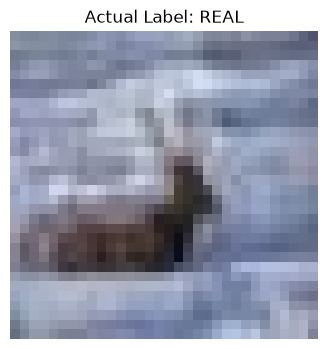

In [19]:
import random
import matplotlib.pyplot as plt

image_index = random.randint(0, len(val_dataset) - 1)

image_tensor, true_label = val_dataset[image_index]

class_names = ["FAKE", "REAL"]

plt.figure(figsize=(4, 4))
plt.imshow(image_tensor.permute(1, 2, 0).numpy())
plt.title("Actual Label: " + class_names[true_label])
plt.axis("off")
plt.show()

In [20]:
image_input = image_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    output = model(image_input)
    probabilities = torch.softmax(output, dim=1)
    predicted_label = torch.argmax(probabilities, dim=1).item()

predicted_class = class_names[predicted_label]
confidence = probabilities[0, predicted_label].item() * 100

print("Actual Label:", class_names[true_label])
print("Predicted Label:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Actual Label: REAL
Predicted Label: REAL
Confidence: 92.35%


In [21]:
# Store activations and gradients
activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# Register hooks on the last convolutional layer
forward_handle = model.conv3.register_forward_hook(forward_hook)

backward_handle = model.conv3.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks registered successfully!")

Grad-CAM hooks registered successfully!


In [22]:
# Clear previous gradients
model.zero_grad()

# Forward pass
output = model(image_input)

# Get the score for the predicted class
score = output[0, predicted_label]

# Backward pass to calculate gradients
score.backward()

# Calculate the weights using average gradients
weights = gradients.mean(dim=(2, 3), keepdim=True)

# Combine feature maps using the weights
cam = (weights * activations).sum(dim=1, keepdim=True)

# Keep only positive contributions
cam = F.relu(cam)

# Normalize the heatmap
cam = cam.squeeze()

cam = cam.detach().cpu().numpy()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

print("Grad-CAM heatmap generated successfully!")
print("Heatmap shape:", cam.shape)

Grad-CAM heatmap generated successfully!
Heatmap shape: (8, 8)


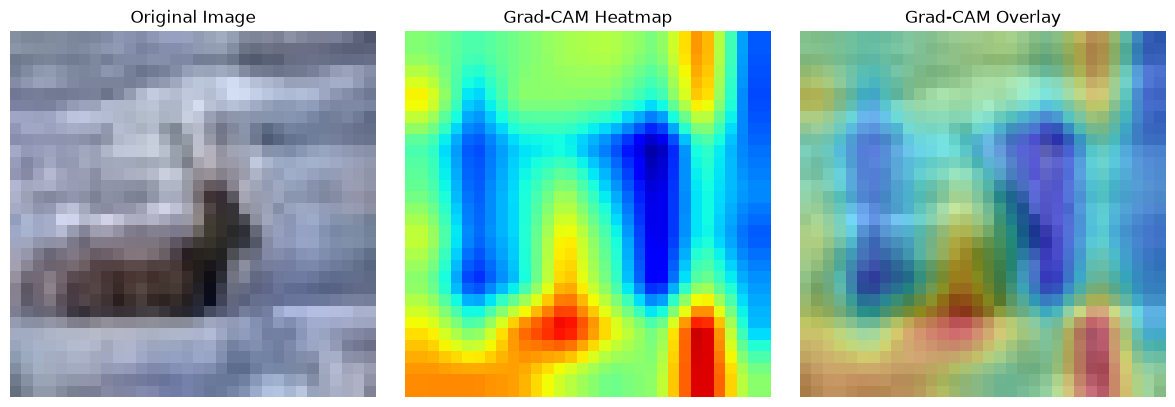

In [23]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Convert the original image tensor to a NumPy array
original_image = image_tensor.permute(1, 2, 0).numpy()

# Resize the heatmap to match the image dimensions
heatmap = cv2.resize(
    cam,
    (original_image.shape[1], original_image.shape[0])
)

# Display original image and heatmap
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45, vmin=0, vmax=1)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

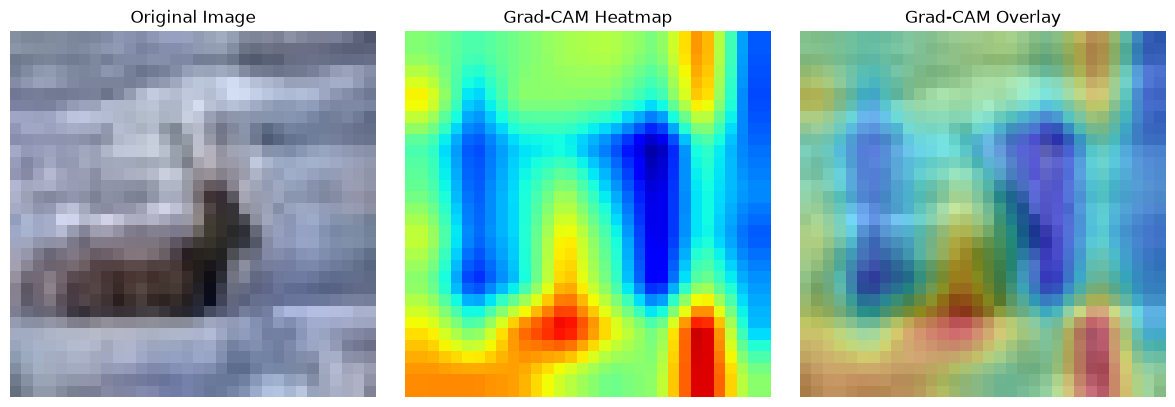

Grad-CAM visualization saved to: c:\Users\KIIT\Desktop\HybridDeepTrace\results\gradcam_real_example.png


In [24]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import numpy as np

PROJECT_ROOT = Path.cwd().parent
RESULTS_PATH = PROJECT_ROOT / "results"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)

original_image = image_tensor.permute(1, 2, 0).numpy()

heatmap = cv2.resize(
    cam,
    (original_image.shape[1], original_image.shape[0])
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45, vmin=0, vmax=1)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()

save_path = RESULTS_PATH / "gradcam_real_example.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Grad-CAM visualization saved to:", save_path)


In [25]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

TEST_PATH = PROJECT_ROOT / "dataset" / "raw" / "CIFAKE" / "test"

transform = transforms.Compose([
    transforms.ToTensor()
])

test_dataset = datasets.ImageFolder(
    root=str(TEST_PATH),
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("Test dataset loaded successfully!")
print("Class mapping:", test_dataset.class_to_idx)
print("Total test images:", len(test_dataset))
print("Total batches:", len(test_loader))

Test dataset loaded successfully!
Class mapping: {'FAKE': 0, 'REAL': 1}
Total test images: 20000
Total batches: 313


In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import torch

# Load the saved best model
model = DeepTraceCNN().to(device)

MODEL_PATH = PROJECT_ROOT / "models" / "deeptrace_cnn.pth"

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

model.eval()

all_test_predictions = []
all_test_labels = []

# Predict on the complete test dataset
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )
        all_test_labels.extend(
            labels.numpy()
        )

# Calculate metrics
test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

print("CNN FINAL TEST RESULTS")
print("-" * 35)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        labels=[0, 1],
        target_names=["FAKE", "REAL"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        all_test_labels,
        all_test_predictions,
        labels=[0, 1]
    )
)

CNN FINAL TEST RESULTS
-----------------------------------
Test Accuracy: 88.78%

Classification Report:
              precision    recall  f1-score   support

        FAKE     0.8806    0.8973    0.8889     10000
        REAL     0.8953    0.8783    0.8867     10000

    accuracy                         0.8878     20000
   macro avg     0.8879    0.8878    0.8878     20000
weighted avg     0.8879    0.8878    0.8878     20000


Confusion Matrix:
[[8973 1027]
 [1217 8783]]


In [27]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
RESULTS_PATH = PROJECT_ROOT / "results"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)

final_results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "FAKE Precision",
        "FAKE Recall",
        "FAKE F1-score",
        "REAL Precision",
        "REAL Recall",
        "REAL F1-score"
    ],
    "Value": [
        0.8878,
        0.8806,
        0.8973,
        0.8889,
        0.8953,
        0.8783,
        0.8867
    ]
})

final_results.to_csv(
    RESULTS_PATH / "cnn_final_test_results.csv",
    index=False
)

print(final_results)
print("\nFinal test results saved successfully!")

           Metric   Value
0   Test Accuracy  0.8878
1  FAKE Precision  0.8806
2     FAKE Recall  0.8973
3   FAKE F1-score  0.8889
4  REAL Precision  0.8953
5     REAL Recall  0.8783
6   REAL F1-score  0.8867

Final test results saved successfully!


In [28]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

required_files = [
    "svm_model.pkl",
    "scaler.pkl",
    "random_forest_model.pkl",
    "xgboost_model.pkl"
]

for filename in required_files:
    file_path = MODEL_DIR / filename

    print(
        filename,
        "->",
        "Found ✅" if file_path.exists() else "Missing ❌"
    )

svm_model.pkl -> Found ✅
scaler.pkl -> Found ✅
random_forest_model.pkl -> Found ✅
xgboost_model.pkl -> Found ✅


In [29]:
import sys

PROJECT_ROOT = Path.cwd().parent
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from feature_extraction import extract_features

print("Feature extraction function imported successfully!")

Feature extraction function imported successfully!


In [32]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [33]:
import numpy as np
from tqdm.auto import tqdm

X_test_features = []
y_test_features = []

for image_path, label in tqdm(test_dataset.samples, desc="Extracting features"):
    features = extract_features(image_path)

    X_test_features.append(features)
    y_test_features.append(label)

X_test_features = np.array(X_test_features, dtype=np.float32)
y_test_features = np.array(y_test_features)

print("\nFeature extraction completed!")
print("Feature matrix shape:", X_test_features.shape)
print("Labels shape:", y_test_features.shape)

Extracting features:   0%|          | 0/20000 [00:00<?, ?it/s]


Feature extraction completed!
Feature matrix shape: (20000, 24)
Labels shape: (20000,)


In [34]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODEL_PATH = PROJECT_ROOT / "models"

svm_model = joblib.load(MODEL_PATH / "svm_model.pkl")
scaler = joblib.load(MODEL_PATH / "scaler.pkl")

rf_model = joblib.load(MODEL_PATH / "random_forest_model.pkl")

xgb_model = joblib.load(MODEL_PATH / "xgboost_model.pkl")

print("All three models loaded successfully!")

All three models loaded successfully!


In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Convert test labels to match traditional ML models
# Traditional models: REAL = 0, FAKE = 1
y_test_traditional = 1 - y_test_features

# Scale features for SVM
X_test_scaled = scaler.transform(X_test_features)

# Make predictions
svm_predictions = svm_model.predict(X_test_scaled)
rf_predictions = rf_model.predict(X_test_features)
xgb_predictions = xgb_model.predict(X_test_features)

# Calculate metrics
models = {
    "SVM": svm_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_traditional, predictions),
        "Precision": precision_score(y_test_traditional, predictions),
        "Recall": recall_score(y_test_traditional, predictions),
        "F1 Score": f1_score(y_test_traditional, predictions)
    })

traditional_results = pd.DataFrame(results)

print("Traditional ML Models - Test Results")
display(traditional_results.round(4))

Traditional ML Models - Test Results


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.8588,0.8759,0.8361,0.8555
1,Random Forest,0.8370,0.8415,0.8303,0.8359
2,XGBoost,0.8486,0.8572,0.8365,0.8467


In [36]:
cnn_results = {
    "Model": "CNN",
    "Accuracy": 0.8878,
    "Precision": 0.8806,
    "Recall": 0.8973,
    "F1 Score": 0.8889
}

cnn_results_df = pd.DataFrame([cnn_results])

final_results = pd.concat(
    [traditional_results, cnn_results_df],
    ignore_index=True
)

print("Hybrid DeepTrace - Final Model Comparison")
display(final_results.round(4))

RESULTS_PATH = PROJECT_ROOT / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

final_results.to_csv(
    RESULTS_PATH / "final_model_comparison.csv",
    index=False
)

print("Comparison saved successfully!")

Hybrid DeepTrace - Final Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.8588,0.8759,0.8361,0.8555
1,Random Forest,0.8370,0.8415,0.8303,0.8359
2,XGBoost,0.8486,0.8572,0.8365,0.8467
3,CNN,0.8878,0.8806,0.8973,0.8889


Comparison saved successfully!
